In [82]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
from google.colab import files

In [83]:
img = files.upload()

Saving link.jpg to link (4).jpg


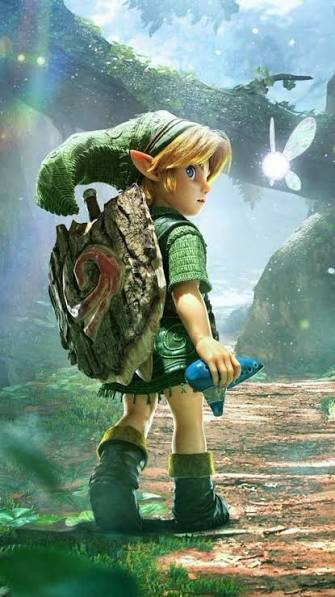

In [84]:
img_rgb = cv2.imread("link.jpg")
cv2_imshow(img_rgb)

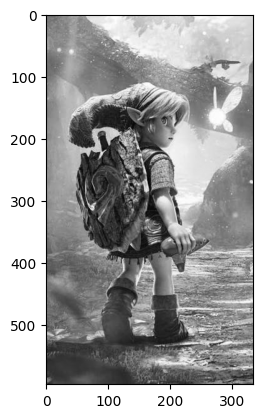

In [85]:
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
plt.imshow(img_gray, cmap='gray')

In [86]:
def calclist(img):
  bars = np.zeros(shape=256, dtype=np.int64)

  for pixel in img.ravel():
    bars[pixel] += 1

  return bars

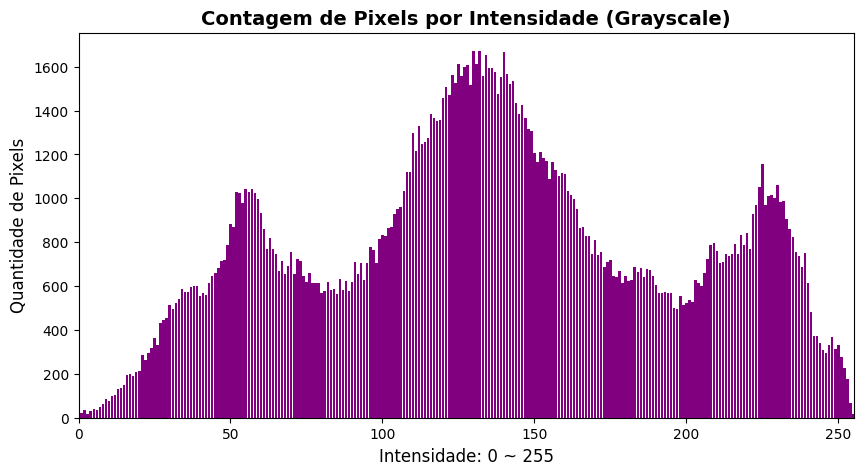

In [87]:
fig, ax = plt.subplots(figsize=(10, 5))

hist = calclist(img_gray)

ax.set_title('Contagem de Pixels por Intensidade (Grayscale)', fontsize=14, fontweight='bold')
ax.set_xlabel('Intensidade: 0 ~ 255', fontsize=12)
ax.set_ylabel('Quantidade de Pixels', fontsize=12)
ax.bar(range(256), hist, color='purple', width=0.8, edgecolor='none')
ax.set_xlim([0, 255])
plt.show()

In [99]:
img_bgrayscale, img_ggrayscale, img_rgrayscale = cv2.split(img_rgb)

placeholder = np.zeros_like(img_bgrayscale)

# Merge back, keeping only the isolated channel active
img_blue  = cv2.merge([img_bgrayscale, placeholder, placeholder])
img_green = cv2.merge([placeholder, img_ggrayscale, placeholder])
img_red   = cv2.merge([placeholder, placeholder, img_rgrayscale])

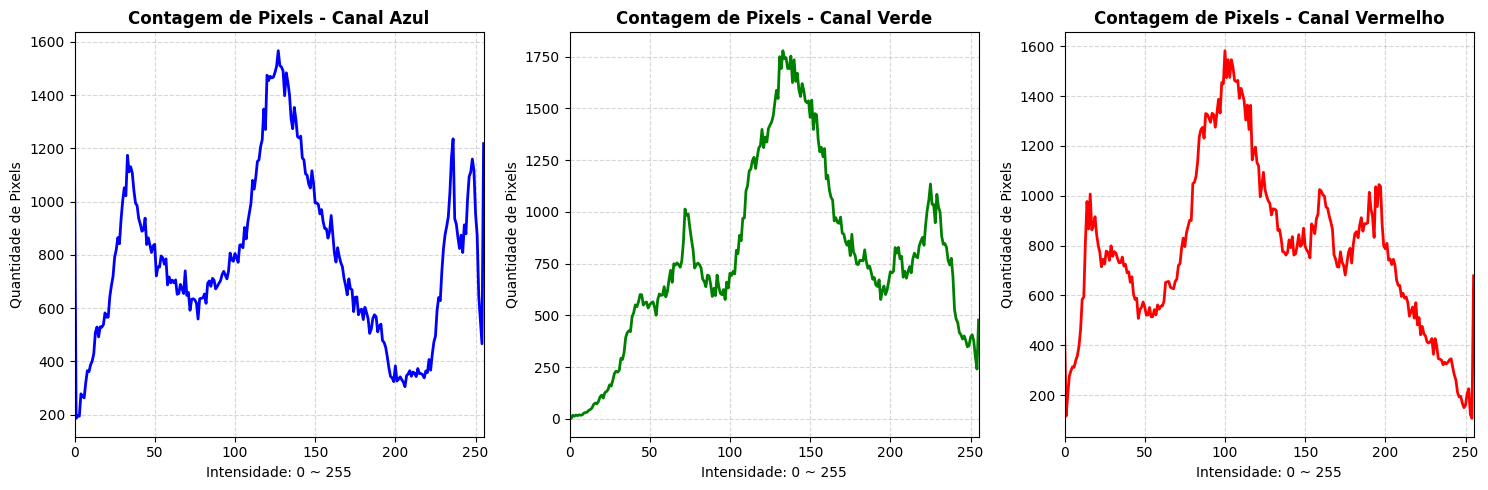

In [104]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Calcular o histograma de intensidades para cada canal de cor separado
hist_blue  = calclist(img_bgrayscale)
hist_green = calclist(img_ggrayscale)
hist_red   = calclist(img_rgrayscale)

# 2. Plotar os dados calculados para cada canal específico
axes[0].plot(range(256), hist_blue, color='blue', linewidth=2)
axes[0].set_title('Contagem de Pixels - Canal Azul', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Intensidade: 0 ~ 255', fontsize=10)
axes[0].set_ylabel('Quantidade de Pixels', fontsize=10)
axes[0].set_xlim([0, 255])
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(range(256), hist_green, color='green', linewidth=2)
axes[1].set_title('Contagem de Pixels - Canal Verde', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Intensidade: 0 ~ 255', fontsize=10)
axes[1].set_ylabel('Quantidade de Pixels', fontsize=10)
axes[1].set_xlim([0, 255])
axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].plot(range(256), hist_red, color='red', linewidth=2)
axes[2].set_title('Contagem de Pixels - Canal Vermelho', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Intensidade: 0 ~ 255', fontsize=10)
axes[2].set_ylabel('Quantidade de Pixels', fontsize=10)
axes[2].set_xlim([0, 255])
axes[2].grid(True, linestyle='--', alpha=0.5)

# 3. Organizar layout e exibir
plt.tight_layout()
plt.show()